# CHAZ tracks

Our ERA5 CHAZ run (TCGI-CRH, 1981–2019, 10 track realizations a year with 40 intensity members
each) against the published ERA5 track files (10 files of 40 members) and IBTrACS. A second run of
ours, with the same seeds and the steering noise the published tracks are consistent with
('ours, diagonal steering', §3), separates the steering from everything else. The forcing and
genesis-index notebooks check the inputs; this one checks what CHAZ makes of them, starting with
US landfall.

`ocr.risks.hurricane.landfall` applies one set of rules to all three:

- 6-hourly nodes interpolated to hourly; IBTrACS from its USA_WIND (1-minute) at synoptic hours
- a US landfall is the first hour on US land (Natural Earth 1:10m at 1/24°) right after an hour
  over water, counted once per storm at its wind in that hour, from 34 kt
- CHAZ rates are per member-year, scaled so the North Atlantic tropical-storm count matches the
  observed one, which leaves where storms go and how strong they are

## Decisions

| | choice | evidence |
| --- | --- | --- |
| landfall rules | hourly tracks, the 1:10m US outline, first crossing from water, from 34 kt, CHAZ scaled to the observed North Atlantic storm count | §1 |
| steering noise | the lower Cholesky factor; the published tracks are consistent with the transposed one, which moves US landfalls by about 5% | §1, §3 |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from ocr.risks.hurricane import landfall, store, tracks

TCGI = 'TCGI_CRH_PI'
OURS, THEIRS, OBS, DIAG = '#2a78d6', '#eb6834', '#52514e', '#1baf7a'
SETS = {'ours': TCGI, 'ours, diagonal steering': f'{TCGI}-steering-diagonal'}
COLORS = {'IBTrACS': OBS, 'published': THEIRS, 'ours': OURS, 'ours, diagonal steering': DIAG}
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
summaries = {
    name: pd.read_csv(store.path(f'{landfall.OUT}/summary_{run}.csv'), index_col=0)
    for name, run in SETS.items()
}


def scaled_column(summary, prefix):
    return summary[next(c for c in summary if c.startswith(f'{prefix} (x'))]


scaled = {
    'IBTrACS': summaries['ours']['IBTrACS'],
    'published': scaled_column(summaries['ours'], 'published'),
    **{name: scaled_column(summary, 'ours') for name, summary in summaries.items()},
}
rows = {
    'IBTrACS': pd.read_parquet(store.path(f'{landfall.OUT}/rows_ibtracs.parquet')),
    'published': pd.read_parquet(store.path(f'{landfall.OUT}/rows_published.parquet')),
    **{
        name: pd.read_parquet(store.path(f'{landfall.OUT}/rows_ours_{run}.parquet'))
        for name, run in SETS.items()
    },
}

## 1. US landfall

In [2]:
keep = [
    'NA TS storms/yr',
    'US landfalls/yr (>= 34 kt)',
    'US landfalls/yr >= 64 kt',
    'US landfalls/yr >= 96 kt',
    'landfall share of NA TS storms',
    'NA TS storms crossing the US coast, share',
    'crossings at >= 34 kt, share',
    'crossings at >= 64 kt, share',
    'NA TS storms with wind at their last track node, share',
    'landfall / 24 h approach peak, median',
    '12 h after / at landfall (>= 64 kt), median',
]
t = pd.DataFrame(scaled).loc[keep]
t['published ÷ IBTrACS'] = t['published'] / t['IBTrACS']
t['ours ÷ IBTrACS'] = t['ours'] / t['IBTrACS']
t['ours ÷ published'] = t['ours'] / t['published']
t['diagonal ÷ ours'] = t['ours, diagonal steering'] / t['ours']
t.style.format('{:.3f}').set_caption(
    '1981–2019; rates per year, CHAZ scaled to the observed North Atlantic storm count'
)

,IBTrACS,published,ours,"ours, diagonal steering",published ÷ IBTrACS,ours ÷ IBTrACS,ours ÷ published,diagonal ÷ ours
NA TS storms/yr,13.385,13.385,13.385,13.385,1.000,1.000,1.000,1.000
US landfalls/yr (>= 34 kt),2.974,2.201,3.078,2.927,0.740,1.035,1.398,0.951
US landfalls/yr >= 64 kt,1.308,0.595,0.945,0.896,0.455,0.722,1.588,0.949
US landfalls/yr >= 96 kt,0.179,0.111,0.224,0.209,0.620,1.246,2.011,0.933
landfall share of NA TS storms,0.222,0.160,0.205,0.203,0.719,0.924,1.285,0.987
"NA TS storms crossing the US coast, share",0.261,0.385,0.398,0.390,1.476,1.529,1.036,0.979
"crossings at >= 34 kt, share",0.853,0.416,0.516,0.520,0.487,0.605,1.241,1.008
"crossings at >= 64 kt, share",0.375,0.112,0.151,0.153,0.298,0.401,1.345,1.016
"NA TS storms with wind at their last track node, share",1.000,0.083,0.309,0.260,0.083,0.309,3.705,0.840
"landfall / 24 h approach peak, median",0.914,0.878,0.905,0.909,0.960,0.990,1.031,1.005


Scaled to the same number of North Atlantic storms, our run makes 1.4 times as many US landfalls
as the published one, and the gap grows with intensity: 1.6 times at 64 kt, 2.0 at 96 kt. The
tracks are not where it comes from. Of North Atlantic storms, 39.8% of our tracks cross the US
coast and 38.5% of theirs. The wind at the crossing is: 52% of our crossings are at 34 kt or more,
against 42% of theirs and 85% of observed ones.

The steering noise accounts for little of it. Our run with the published run's steering noise
makes 5% fewer US landfalls than ours (0.95 at 34 and at 64 kt), from slightly fewer crossings
(39.0%), with the same wind at the crossing (52%).

Both CHAZ runs cross the coast about 1.5 times as often as observed storms do, because a CHAZ
track runs on after its storm has died. The crossing share counts tracks, not living storms.

By coast, our hurricane landfalls are closer to observed than the published ones everywhere but
Georgia–the Carolinas, where all three CHAZ sets are about a third of observed. The diagonal
steering moves some from Florida to the Gulf and the Carolinas:

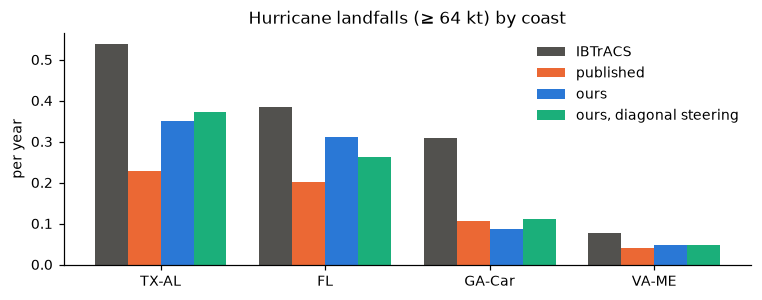

In [3]:
regions = ['TX-AL', 'FL', 'GA-Car', 'VA-ME']
fig, ax = plt.subplots(figsize=(7, 2.8))
x = np.arange(len(regions))
for k, (name, s) in enumerate(scaled.items()):
    ax.bar(
        x + (k - 1.5) * 0.2,
        [s[f'{r} landfalls/yr >= 64 kt'] for r in regions],
        0.2,
        color=COLORS[name],
        label=name,
    )
ax.set_xticks(x, regions)
ax.set(ylabel='per year', title='Hurricane landfalls (≥ 64 kt) by coast')
ax.legend(frameon=False)
fig.tight_layout()

## 2. How intensity members end

A CHAZ track runs its full course whatever happens to the storm; each intensity member carries a
wind along it until the intensity model stops. It stops after two 12-hourly steps at or below
35 kt once the storm has been above 35 kt ('fell to 35 kt'), after a step below 10 kt, or at the
end of the track. The share of members still carrying wind where their track ends separates the
two runs more than anything else in §1.

In [4]:
def ends(r):
    na = r[r['na_ts']]
    early = na['end_before_track_h'] > 0
    return {
        **na['end_rule']
        .value_counts(normalize=True)
        .reindex(['track end', 'fell to 35 kt', 'other'])
        .fillna(0)
        .add_prefix('ends: '),
        'wind ends before its track': early.mean(),
        'hours before track end, median (those)': na.loc[early, 'end_before_track_h'].median(),
        'last wind (kt), median': na['end_wind'].median(),
        'members': len(na),
    }


pd.DataFrame({k: ends(r) for k, r in rows.items() if k != 'IBTrACS'}).style.format(
    '{:.3f}'
).set_caption('North Atlantic tropical-storm members, 1981–2019')

,published,ours,"ours, diagonal steering"
ends: track end,0.181,0.394,0.339
ends: fell to 35 kt,0.569,0.484,0.530
ends: other,0.251,0.122,0.131
wind ends before its track,0.917,0.691,0.740
"hours before track end, median (those)",102.000,96.000,108.000
"last wind (kt), median",22.653,27.261,26.258
members,198132.000,204841.000,204068.000


In the published files, 92% of North Atlantic members stop before their track ends, against 69%
in ours. Ours run to the end of the track twice as often (39% against 18%). Theirs stop more often
after falling to 35 kt (57% against 48%), and twice as often for the remaining reasons, a 12-hour
step predicted below 10 kt or missing predictors (25% against 12%). The diagonal steering moves
ours a little toward theirs (74% stop before the track ends) and leaves most of the difference.

In [5]:
def at_crossing(r):
    c = r[r['na_ts'] & r['crosses']]
    h = c['end_h_after_lf']
    return {
        'wind ended before the crossing': (h < 0).mean(),
        'ended 0–24 h after': ((h >= 0) & (h <= 24)).mean(),
        'ended 24–48 h after': ((h > 24) & (h <= 48)).mean(),
        'later, or at the end of the track': (h > 48).mean(),
        'ends over land, of those ending within 48 h': c.loc[
            (h >= 0) & (h <= 48), 'end_on_land'
        ].mean(),
        'members': len(c),
    }


pd.DataFrame({k: at_crossing(r) for k, r in rows.items()}).style.format('{:.3f}').set_caption(
    'North Atlantic tropical-storm members whose track crosses the US coast: when the wind ends, from the crossing hour'
)

,IBTrACS,published,ours,"ours, diagonal steering"
wind ended before the crossing,0.000,0.379,0.288,0.277
ended 0–24 h after,0.125,0.310,0.324,0.317
ended 24–48 h after,0.235,0.140,0.158,0.171
"later, or at the end of the track",0.640,0.171,0.230,0.235
"ends over land, of those ending within 48 h",0.667,0.884,0.931,0.937
members,136.000,76204.000,81591.000,79570.000


Of the members whose track crosses the US coast, 38% of the published ones have lost their wind
before the crossing, against 29% of ours and 28% with the diagonal steering. Most of the
difference in wind at the crossing (§1) comes from this.

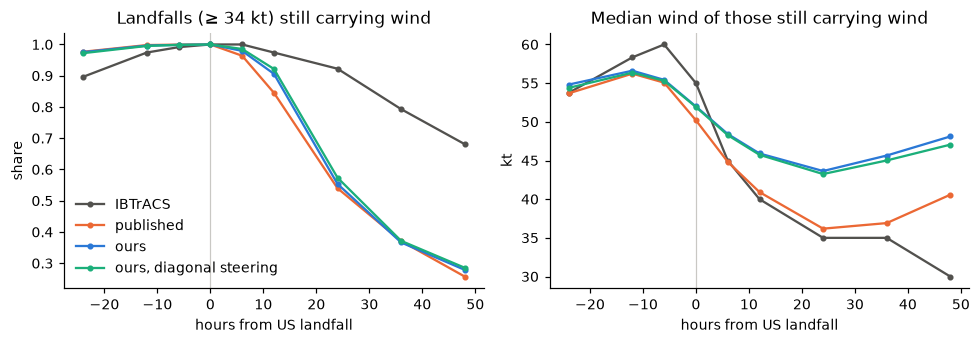

In [6]:
hours = [-24, -12, -6, 0, 6, 12, 24, 36, 48]
cols = {h: ('lf_wind' if h == 0 else f'lf_w{h:+d}') for h in hours}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for name, r in rows.items():
    lf = r[r['lf_wind'] >= landfall.TS]
    w = lf[[cols[h] for h in hours]].to_numpy()
    axes[0].plot(
        hours, np.isfinite(w).mean(axis=0), color=COLORS[name], marker='o', ms=3, label=name
    )
    axes[1].plot(hours, np.nanmedian(w, axis=0), color=COLORS[name], marker='o', ms=3, label=name)
axes[0].set(
    xlabel='hours from US landfall', ylabel='share', title='Landfalls (≥ 34 kt) still carrying wind'
)
axes[1].set(
    xlabel='hours from US landfall', ylabel='kt', title='Median wind of those still carrying wind'
)
axes[0].legend(frameon=False)
for ax in axes:
    ax.axvline(0, color='#c9c8c4', lw=0.8, zorder=0)
fig.tight_layout()

Once ashore, the CHAZ runs lose members at the same pace, and much faster than observed storms
end: a day after landfall about 55% still carry wind, against about 92% of observed storms. Those
that survive weaken more slowly in both of ours, about 46 kt 12 hours after landfall against about
41 kt in the published files and 40 kt observed.

## 3. Steering noise

CHAZ moves a storm with the 0.8·850 + 0.2·250 hPa wind: the monthly mean interpolated to the day,
plus A·ε with A a factor of the daily wind covariance and ε unit-variance noise correlated in
time, plus beta drift. The
tutorial's A files hold the lower Cholesky factor, and so do ours (forcing notebook, §3); the
tutorial's notebook code as written transposes it, which leaves the off-diagonal entries zero.
`ocr.risks.hurricane.tracks` takes track motion minus the mean steering and a fitted drift, and
compares the spread and u–v correlation of what is left with what each reading of A predicts.
North Atlantic, 10–30°N, 2017, the year the tutorial publishes forcing for (ours matches it).
Successive steps of a track are not independent, so the step counts overstate the sample.

In [7]:
f = tracks.Forcing(2017, store.tutorial)
fs = store.s3()
published = []
for i in range(10):
    with fs.open(f'{store.PUBLISHED_TRACKS}/global_2019_2ens{i:03d}_pre.nc', 'rb') as fh:
        published.append(
            tracks.steps(xr.open_dataset(fh, engine='scipy', decode_times=False).load(), f)
        )
sets = {'published': np.concatenate(published)}
for name, run in SETS.items():
    sets[name] = np.concatenate(
        [
            tracks.steps(
                xr.open_dataset(
                    store.path(f'{store.RUNS}/{run}/2017_r{r:03d}.nc'), decode_times=False
                ),
                f,
            )
            for r in range(10)
        ]
    )
tracks.table(sets).style.format(
    {'steps': '{:.0f}', 'sd u (m/s)': '{:.2f}', 'sd v (m/s)': '{:.2f}', 'r(u, v)': '{:.3f}'}
)

The run with the off-diagonal entries zeroed calibrates the test. Its tracks measure a spread of
3.07 and 2.54 m s⁻¹, nearly the published 3.08 and 2.55, and an r of 0.069 though its noise has
none, so the test resolves r to about ±0.07. The published tracks' −0.014 is far from the lower
factor's 0.14 and consistent with the transposed factor; ours (0.136) match the lower factor. We
keep the lower factor, which reproduces the covariance.

## Summary and open items

Our run and the published ERA5 tracks reach the US coast at nearly the same rate. They differ in how
long the intensity members last: the published members stop before reaching the coast more often.
So our run makes 1.4 times as many US landfalls and 1.6 times as many hurricane landfalls as the
published one, which takes CHAZ from 0.46 to 0.72 of the observed hurricane landfall rate. The
steering noise, the one difference in the track model we know of, accounts for little of that:
with the published run's steering, our run makes about 5% fewer landfalls and its members reach
the coast with wind as often as before (§1, §2).

Open:

- **What stops the published members sooner.** The intensity code behind the published files,
  in particular its land term and stopping rules, is a question for the CHAZ authors.
- **Which storms the published files keep.** They keep some storms the public code drops
  (genesis-index notebook, §4), so other selection differences could shift these distributions.
- **Over land.** All CHAZ sets lose members over land far faster than observed storms end, and
  all cross the coast about 1.5 times as often as observed because tracks outlive storms. A
  landfall statistic needs the wind, not the track alone.
- **Not yet covered.** Basin counts and lifetime-maximum intensity against IBTrACS, and tracks
  away from the US.